# Customer Churn & CLV — Churn Definition and Feature Engineering

## Objective

In a subscription business (telecom, gyms, Netflix) customers cancel a contract, so churn is a clear event. In an online retailer nobody cancels: customers simply **stop buying**. This means that churn **has to be defined**.

My definition, based on the EDA:

> **Churn = an active customer (at least one purchase in the last 180 days) who doesn't make any purchase in the next 90 days.**

The most important point of this notebook is to avoid **data leakage**: the model must not see information from the future. For this reason I build the dataset with **snapshots** (cut-off dates):

- The **features** are calculated only with the 180 days **before** the snapshot date.
- The **label** (churn yes/no) is calculated only with the 90 days **after** the snapshot date.

In [1]:
# Import all the libraries necessary for this section
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the clean sales and returns
sales_df = pd.read_csv("../data/processed/sales_clean.csv", parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
returns_df = pd.read_csv("../data/processed/returns_clean.csv", parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})

print(sales_df.shape, returns_df.shape)

(776579, 9) (17586, 9)


In [3]:
# Create a table with one row per order (invoice)
orders_df = (
    sales_df
    .groupby(["CustomerID", "Invoice"])
    .agg(date=("InvoiceDate", "min"), value=("Revenue", "sum"), items=("Quantity", "sum"))
    .reset_index()
    .sort_values(["CustomerID", "date"])
)

orders_df.head()

,CustomerID,Invoice,date,value,items
0,12346,499763,2010-03-02 13:08:00,27.05,5
1,12346,513774,2010-06-28 13:53:00,142.31,19
2,12346,541431,2011-01-18 10:01:00,77183.60,74215
3,12347,529924,2010-10-31 14:20:00,611.53,509
4,12347,537626,2010-12-07 14:57:00,711.79,319


## 1. Snapshot function

The function receives a snapshot date and returns one row per active customer with their features and their churn label.

| Feature | Meaning |
|---|---|
| `recency_days` | Days since the last order |
| `frequency`, `frequency_30d`, `frequency_90d` | Orders in the last 180 / 30 / 90 days |
| `monetary`, `monetary_30d`, `monetary_90d` | Revenue in the last 180 / 30 / 90 days |
| `avg_order_value`, `avg_items_per_order` | Size of the basket |
| `avg_days_between_orders` | Purchase cycle of the customer (empty if only 1 order) |
| `days_since_first_order` | First order inside the 180-day window |
| `spend_trend` | Recent vs older spend, from -1 (all spend was older) to +1 (all spend is recent) |
| `n_products` | Number of different products bought |
| `return_rate` | Value returned / value purchased |
| `is_uk` | Customer from the United Kingdom |
| `peak_season_ahead` | The next 90 days include the September–November peak |

In [4]:
LOOKBACK_DAYS = 180   # history used to calculate the features
HORIZON_DAYS = 90     # future window used to define churn


def build_snapshot(snapshot_date):

    snapshot = pd.Timestamp(snapshot_date)
    start = snapshot - pd.Timedelta(days=LOOKBACK_DAYS)
    end = snapshot + pd.Timedelta(days=HORIZON_DAYS)

    # 1. Data BEFORE the snapshot (used for the features)
    past_orders = orders_df[(orders_df["date"] >= start) & (orders_df["date"] < snapshot)]
    past_lines = sales_df[(sales_df["InvoiceDate"] >= start) & (sales_df["InvoiceDate"] < snapshot)]
    past_returns = returns_df[(returns_df["InvoiceDate"] >= start) & (returns_df["InvoiceDate"] < snapshot)]

    # 2. RFM and basket features
    customers = past_orders.groupby("CustomerID")

    features = pd.DataFrame({
        "recency_days": (snapshot - customers["date"].max()).dt.days,
        "frequency": customers.size(),
        "monetary": customers["value"].sum(),
        "avg_order_value": customers["value"].mean(),
        "avg_items_per_order": customers["items"].mean(),
        "days_since_first_order": (snapshot - customers["date"].min()).dt.days,
        "avg_days_between_orders": customers["date"].apply(lambda d: d.diff().dt.days.mean()),
    })

    # 3. Recent activity (last 30 and 90 days)
    for days in [30, 90]:
        recent = past_orders[past_orders["date"] >= snapshot - pd.Timedelta(days=days)].groupby("CustomerID")
        features[f"frequency_{days}d"] = recent.size().reindex(features.index).fillna(0)
        features[f"monetary_{days}d"] = recent["value"].sum().reindex(features.index).fillna(0)

    # 4. Spend trend: recent spend (last 90 days) vs older spend (90-180 days ago)
    older_spend = features["monetary"] - features["monetary_90d"]
    features["spend_trend"] = (features["monetary_90d"] - older_spend) / (features["monetary_90d"] + older_spend)

    # 5. Product variety and country
    features["n_products"] = past_lines.groupby("CustomerID")["StockCode"].nunique()
    features["is_uk"] = (past_lines.groupby("CustomerID")["Country"].first() == "United Kingdom").astype(int)

    # 6. Return rate
    returned_value = past_returns.groupby("CustomerID")["Revenue"].sum().abs()
    features["return_rate"] = (returned_value.reindex(features.index).fillna(0) / features["monetary"]).clip(0, 1)

    # 7. Seasonality: does the prediction window include the Q4 peak?
    features["peak_season_ahead"] = int(snapshot.month in [8, 9, 10])

    # 8. Label: did the customer buy in the next 90 days? (data AFTER the snapshot)
    future_orders = orders_df[(orders_df["date"] >= snapshot) & (orders_df["date"] < end)]
    features["churn"] = (~features.index.isin(future_orders["CustomerID"])).astype(int)

    features["snapshot"] = snapshot_date

    return features.reset_index()

In [5]:
# Test the function with one snapshot
example = build_snapshot("2011-09-09")

example.head()

,CustomerID,recency_days,frequency,monetary,avg_order_value,avg_items_per_order,days_since_first_order,avg_days_between_orders,frequency_30d,monetary_30d,frequency_90d,monetary_90d,spend_trend,n_products,is_uk,return_rate,peak_season_ahead,churn,snapshot
0,12347,37,3,1603.68,534.56,318.666667,154,58.0,0.0,0.0,1.0,584.91,-0.27054,50,0,0.0,1,0,2011-09-09
1,12348,156,1,327.00,327.00,268.000000,156,NaN,0.0,0.0,0.0,0.00,-1.00000,4,0,0.0,1,0,2011-09-09
2,12352,170,2,240.66,120.33,63.000000,175,5.0,0.0,0.0,0.0,0.00,-1.00000,7,0,0.5,1,0,2011-09-09
3,12353,112,1,89.00,89.00,20.000000,112,NaN,0.0,0.0,0.0,0.00,-1.00000,4,0,0.0,1,1,2011-09-09
4,12354,140,1,1079.40,1079.40,530.000000,140,NaN,0.0,0.0,0.0,0.00,-1.00000,58,0,0.0,1,1,2011-09-09


## 2. Train, validation and test sets

A random `train_test_split` would be wrong here: the model would learn with 2011 data to predict 2010 and the same customer would appear in train and test. So I split **by time**, with one snapshot every quarter:

| Set | Snapshot dates | Use |
|---|---|---|
| Train | 2010-06-11, 2010-09-09, 2010-12-09, 2011-03-11 | Fit the models |
| Validation | 2011-06-11 | Early stopping and model choice |
| Test | 2011-09-09 | Final evaluation (only once) |

The test set is September → December 2011, the same season in which a real retention campaign before Christmas would be launched.

In [6]:
# Define the snapshot dates of each set
TRAIN_SNAPSHOTS = ["2010-06-11", "2010-09-09", "2010-12-09", "2011-03-11"]
VALID_SNAPSHOT = "2011-06-11"
TEST_SNAPSHOT = "2011-09-09"

# Build all the snapshots
snapshots = []

for date in TRAIN_SNAPSHOTS:
    snapshots.append(build_snapshot(date).assign(set="train"))

snapshots.append(build_snapshot(VALID_SNAPSHOT).assign(set="validation"))
snapshots.append(build_snapshot(TEST_SNAPSHOT).assign(set="test"))

churn_df = pd.concat(snapshots, ignore_index=True)

churn_df.shape

(17675, 20)

In [7]:
# Check the number of customers and the churn rate of each snapshot
snapshot_summary = (
    churn_df
    .groupby(["snapshot", "set"])
    .agg(customers=("CustomerID", "count"), churn_rate=("churn", "mean"))
    .reset_index()
)

snapshot_summary

,snapshot,set,customers,churn_rate
0,2010-06-11,train,2634,0.506454
1,2010-09-09,train,2811,0.383493
2,2010-12-09,train,3467,0.641765
3,2011-03-11,train,3348,0.576762
4,2011-06-11,validation,2640,0.505303
5,2011-09-09,test,2775,0.384865


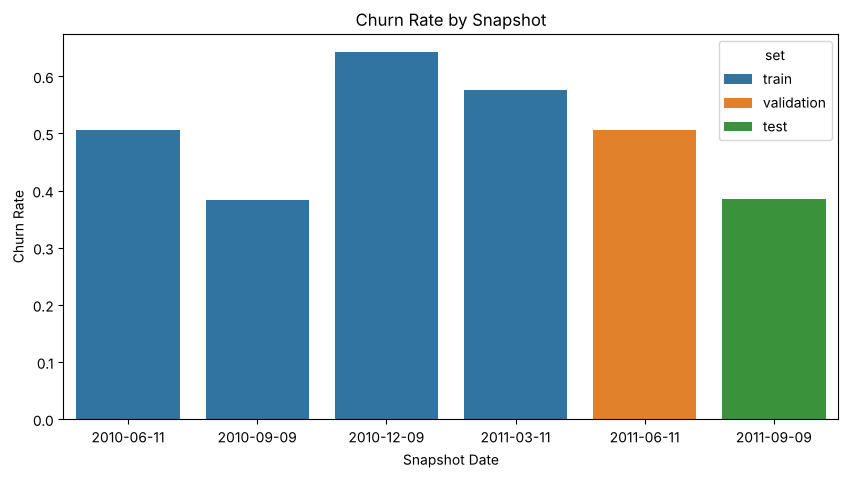

In [8]:
# Plot the churn rate of each snapshot
plt.figure(figsize=(10, 5))

sns.barplot(data=snapshot_summary, x="snapshot", y="churn_rate", hue="set")

plt.title("Churn Rate by Snapshot")
plt.xlabel("Snapshot Date")
plt.ylabel("Churn Rate")
plt.show()

In [9]:
# Check the missing values of the final dataset
churn_df.isna().sum()

CustomerID                    0
recency_days                  0
frequency                     0
monetary                      0
avg_order_value               0
avg_items_per_order           0
days_since_first_order        0
avg_days_between_orders    8016
frequency_30d                 0
monetary_30d                  0
frequency_90d                 0
monetary_90d                  0
spend_trend                   0
n_products                    0
is_uk                         0
return_rate                   0
peak_season_ahead             0
churn                         0
snapshot                      0
set                           0
dtype: int64

`avg_days_between_orders` is empty for customers with only one order (there is no gap to calculate). I keep it empty on purpose: it means "this customer hasn't repeated yet", which is information for the model.

In [10]:
# Save the dataset for the modeling notebook
OUTPUT_PATH = Path("../data/processed/churn_dataset.csv")

churn_df.to_csv(OUTPUT_PATH, index=False)

print(f"Churn dataset saved to: {OUTPUT_PATH}")
print(f"Final shape: {churn_df.shape}")

Churn dataset saved to: ../data/processed/churn_dataset.csv
Final shape: (17675, 20)


## Conclusions

- Churn was defined as **no purchase in the next 90 days** for customers active in the last 180 days.
- The dataset was built with **6 quarterly snapshots**, where the features only use the past and the label only uses the future. This avoids data leakage.
- The churn rate changes a lot depending on the season: **38% when the next 90 days include the Q4 peak and 64% just after Christmas**. This confirms the seasonality seen in the EDA and justifies the `peak_season_ahead` feature.
- Final dataset: 17,675 rows (customer × snapshot) and 16 features.